<a href="https://colab.research.google.com/github/handanaltuner/veri-bilimi-calisma-notlari/blob/main/Tech_%C4%B0stanbul_6_Odev__Handan_Altuner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler


In [ ]:
from google.colab import drive

df=pd.read_csv('/content/drive/MyDrive/Techİstanbul/enerji_tuketimi.csv')

X=df[['sicaklik']].values
y=df[['enerji']].values.reshape(-1,1)



In [ ]:
scaler_X=StandardScaler()
scaler_y=StandardScaler()

X_scaled=scaler_X.fit_transform(X)
y_scaled=scaler_y.fit_transform(y)

In [ ]:
X_b=np.c_[np.ones((len(X_scaled),1)), X_scaled] #bias ekleme

In [ ]:
ogrenme_orani=0.1

n_iterations=1000,
veri_sayi=len(X_scaled) #hiper parametreler #öğrenme kuralları

In [ ]:
weights=np.random.randn(2,1) #ağırlık belirlenmesi

print("Ağırlıklar:" , weights)

Ağırlıklar: [[-0.70991793]
 [ 1.10030142]]


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model=Sequential([
    Dense(units=10,activation='relu',  input_shape=[1,]),
    Dense(units=1)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='sgd', loss='mean_squared_error')

In [ ]:
model.fit(X_scaled,y_scaled,epochs=1000, verbose=0)

In [ ]:
print("Eğitim tamamlandı")

Eğitim tamamlandı


In [ ]:
y_pred_linear=X_b.dot(weights)
y_pred_ann=model.predict(X_scaled)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


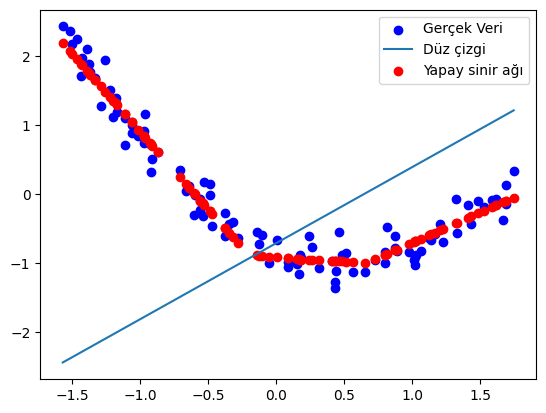

In [ ]:
plt.scatter(X_scaled, y_scaled,color='blue', label='Gerçek Veri')
plt.plot(X_scaled, y_pred_linear, label='Düz çizgi')
plt.scatter(X_scaled, y_pred_ann, color='red', label='Yapay sinir ağı')
plt.legend()

plt.show()
#